# An old binary population at low redshift, seen with JWST

Question: how massive must a simple stellar population be before NIRCam
would detect it in a nearby galaxy?

The example uses one BPASS population: binary, broken power-law IMF with
\(\alpha = 1.35\) and \(M_\mathrm{max} = 300\,M_\odot\) (`imf135_300`),
solar metallicity, age \(10\,\mathrm{Gyr}\) (\(\log_{10}(\mathrm{age/yr}) = 10.0\)).
That age is within the range the explorer draws. The API also serves the
grid out to \(\log_{10}(\mathrm{age/yr}) = 11\).

Set `API` to the bib instance you are querying. The calculation assumes a
point-source limit. Replace `M_LIMIT` with a depth from the exposure-time
calculator for the exposure you actually have. This is one instantaneous
burst, not a star-formation history.


In [1]:
import json
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np

API = "https://cyan-quail.lnx.warwick.ac.uk"
IMF = "imf135_300"
Z_LABEL = "z020"
LOG_AGE = 10.0          # 10 Gyr
REDSHIFT = 0.1
FILTER = "jwst.f200w"
M_LIMIT = 28.0          # assumed 5σ point-source limit, AB mag


def get(path, **params):
    query = "?" + urlencode(params) if params else ""
    with urlopen(API + path + query, timeout=120) as response:
        return json.load(response)


## The population and its SED

The catalogue call selects v2.2.1, so there is no \(\alpha\)-element tag.
The plotted spectrum is the display grid (a few thousand points). Photometry
below is computed on the server from the native 1 Å grid.


population 307: 2.2.1  imf135_300  z020  binary
log age 10.0   lsun_per_angstrom (rest frame)   2315 wavelength points


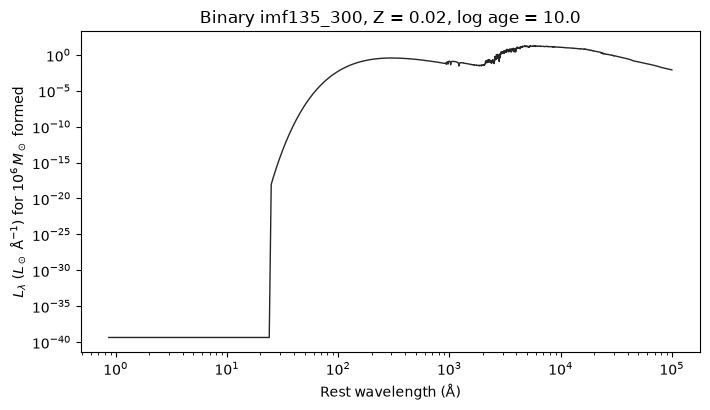

In [2]:
rows = get(
    "/api/v1/populations",
    release="2.2.1",
    imf=IMF,
    z_label=Z_LABEL,
    pop_type="bin",
)
rows = [row for row in rows if row["alpha_label"] is None and not row["is_synthetic"]]
if len(rows) != 1:
    raise SystemExit(f"expected one population, found {len(rows)}")
pop = rows[0]
print(f"population {pop['id']}: {pop['release']}  {pop['imf']}  {pop['z_label']}  binary")

sed = get(
    f"/api/v1/populations/{pop['id']}/sed",
    log_age=LOG_AGE,
    resolution="display",
    mass=1e6,
)
wave = np.asarray(sed["wavelength"], dtype=float)
lum = np.asarray(sed["flux"], dtype=float)
print(f"log age {sed['log_age']}   {sed['flux_unit']}   {wave.size} wavelength points")

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(wave, lum, color="0.15", lw=1.0)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Rest wavelength (Å)")
ax.set_ylabel(r"$L_\lambda$ ($L_\odot$ Å$^{-1}$) for $10^6\,M_\odot$ formed")
ax.set_title(f"Binary {IMF}, Z = 0.02, log age = {sed['log_age']}")
fig.tight_layout()
plt.show()


## Apparent magnitude, then the minimum mass

`GET /api/v1/photometry` scales the mass, applies any dust in the rest frame,
redshifts with the same flat ΛCDM as the rest of bib
(\(H_0 = 70\), \(\Omega_m = 0.3\)), and integrates the NIRCam F200W curve.
No dust is included here.

A brighter population has a smaller AB magnitude. If \(m(M_\mathrm{ref})\)
is the apparent magnitude at the reference mass,

\[
M_\mathrm{min}
  = M_\mathrm{ref}\,
    10^{0.4\,[m(M_\mathrm{ref}) - m_\mathrm{lim}]}.
\]


In [3]:
photo = get(
    "/api/v1/photometry",
    population_id=pop["id"],
    log_age=LOG_AGE,
    filters=FILTER,
    mass=1e6,
    redshift=REDSHIFT,
)
row = photo["photometry"][0]
m_ref = row["ab_mag"]
distance = photo["luminosity_distance_mpc"]
print(f"{row['display_name']} at z = {REDSHIFT}: m_AB = {m_ref:.3f} for 10^6 Msun")
print(f"D_L = {distance:.2f} Mpc   ({photo['cosmology']})")
print(f"filter coverage of the SED = {row['coverage']}")

m_min = 1.0e6 * 10 ** (0.4 * (m_ref - M_LIMIT))
print(f"assumed limit m_AB = {M_LIMIT:.1f}")
print(f"minimum formed mass ≈ {m_min:.3e} Msun")


JWST F200W at z = 0.1: m_AB = 29.022 for 10^6 Msun
D_L = 460.30 Mpc   (flat ΛCDM, H₀=70 km/s/Mpc, Ωm=0.3)
filter coverage of the SED = 1.0
assumed limit m_AB = 28.0
minimum formed mass ≈ 2.563e+06 Msun
